# Internet Aesthetics-- Data Exploration + Prep

1. How much data? What's in it? What format?
2. Features and outcome variables
3. Missing data-- what to do about it
4. Cleaning
5. Distributions-- means and most common values
6. Getting ready for modeling-- encoding, scaling, normalizing
7. Shapes of the features-- SVD (PCA for text) and t-SNE
8. Save

**Main table:** the Hugging Face aesthetics-wiki (its lists are already split up, and every aesthetic has a short `overview` text).


From Zenodo-- only uses 2 small CSVs: decades (to fill the ones Hugging Face is missing) and the wiki's "related aesthetic" links.

## Setup

In [1]:
%pip install -q pandas matplotlib scikit-learn pillow pyarrow kagglehub


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
!mkdir -p data/raw data/clean

!wget -q "https://huggingface.co/datasets/ninar12/aesthetics-wiki/resolve/main/data/train-00000-of-00001.parquet" -O data/raw/aesthetics_wiki.parquet
!unzip -q -o data/raw/AestheticsCV_zenodo.zip "wiki_ecosystem.csv" "wiki_ecosystem_edges.csv" -d data/raw

!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/text_utils.py" -O text_utils.py

!ls -la data/raw

unzip:  cannot find or open data/raw/AestheticsCV_zenodo.zip, data/raw/AestheticsCV_zenodo.zip.zip or data/raw/AestheticsCV_zenodo.zip.ZIP.
total 4580
drwxrwxrwx+ 2 codespace codespace    4096 Nov 21 18:36 .
drwxrwxrwx+ 4 codespace root         4096 Nov 21 18:36 ..
-rw-rw-rw-  1 codespace codespace 4678728 Nov 21 18:36 aesthetics_wiki.parquet


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split

from text_utils import get_top_words

In [14]:
hf_df = pd.read_parquet("data/raw/aesthetics_wiki.parquet")

print(hf_df.shape)
print(list(hf_df.columns))
display(hf_df.head())

(1022, 13)
['title', 'description', 'keywords_spacy', 'alt_titles', 'overview', 'related_aesthetics', 'related_media', 'extract_decade', 'key_motifs', 'related_brands', 'key_values', 'key_colours', 'fashion_sentences']


,title,description,keywords_spacy,alt_titles,overview,related_aesthetics,related_media,extract_decade,key_motifs,related_brands,key_values,key_colours,fashion_sentences
0,Mallsoft,Mallsoft\n\n\n\n\nShop... till you drop.\n\n\n...,"[conceptualized, struggling, minimal, seriesre...","[Mallcore, Mallwave]",Mallsoft's approach to shopping malls is based...,"[After, Hours, Arcadecore, Boujee, Corporate, ...","[Dan, Bell, Dead, Mall, Series, Retail, Archae...",2010s,"[Shopping malls (empty and full), mall food, m...","[Abercrombie and Fitch, Aeropostale, American ...","[Shop till you drop, exploration]","[Pink, teal, mint green, purple, black, white,...","Fashion-wise, Mallsoft can borrow from a varie..."
1,Femme Fatale,Femme Fatale\n\n\n\n\nBlack Widow (played by S...,"[femme, blue, fictionsuccubus, portrays, achie...","[Seductress, Vixen, Temptress, Vamp, Siren, En...","The ""Femme Fatale"" trope is a collection of im...",None,None,1940s,"[Mystery, intelligence, beauty, seduction, power]",None,"[Enticement, scheming, heartlessness, lust]","[Red, black, dark green, dark blue, metallic t...","A femme fatale will be known to wear dark, sex..."
2,Indicolite,"Indicolite\n\n\n\n\n\n\nOther names\nGlaucous,...","[blue, regards, white, tan, emphasis, better, ...","[Glaucous, Alice Blue]",The 'Indicolite' aesthetic is based on the aes...,None,None,2020s,"[Diamonds, water, clouds, vintage statues]",None,None,"[Blue, indigo, cyan, white, grey]",
3,Kingcore,"Kingcore\n\n\n\n\n\n\nKey motifs\nControl, lea...","[blue, duty, purple, long, princecore, seen, c...",None,The 'Kingcore' aesthetic is based on the theme...,None,None,NaN,"[Control, leadership, war, crowns, royal lifes...",None,"[Power, money, hedonism, conquest, status, dut...","[Gold, royal blue, black, white, purple, red]",
4,Onii Kei,Onii Kei Onii Kei (literal elder brother style...,"[dresses, counterpart, necked, style, sexy, ma...",None,Japanese fashion is often referred to as 'Onii...,None,None,NaN,None,None,None,None,


In [15]:
hf_df.notna().mean().round(2)

title                 1.00
description           1.00
keywords_spacy        1.00
alt_titles            0.46
overview              1.00
related_aesthetics    0.68
related_media         0.18
extract_decade        0.53
key_motifs            0.77
related_brands        0.18
key_values            0.66
key_colours           0.79
fashion_sentences     1.00
dtype: float64

In [16]:
favorites = ["Vaporwave", "Frutiger Aero", "Webcore", "Weirdcore", "Dreamcore", "Seapunk"]

display(hf_df[hf_df["title"].isin(favorites)][["title", "extract_decade", "key_motifs", "key_colours", "key_values", "overview"]])

,title,extract_decade,key_motifs,key_colours,key_values,overview
295,Dreamcore,NaN,None,"[Rainbow, blue, green, pink, white, etc.]",[Capture a dream or a feeling of a dream in su...,The aesthetics of Dreamcore are based on surre...
548,Webcore,1990s,"[Oldschool emojis, web graphics, Geocities and...","[Grey, blue, white]",[Individuality],"Despite the lack of a clear ""rainbow"" on the h..."
712,Seapunk,2000s,"[The ocean/sea, aquatic life, mermaids]","[Blue, green, purple, teal, cyan]",[Sea life],"Despite the overwhelming amount of sexiness, t..."
809,Weirdcore,NaN,"[Liminal space, cursed images, low quality JPE...",None,"[Confusion, discomfort, nostalgia, dread]","The origins of Weirdcore are uncertain, but it..."
884,Vaporwave,2010s,"[Drug use and distorted/dream-like imagery, Ja...","[Pastel pinks and blues, white, neon pinks and...",None,Despite the lack of clarity in the 'Viberian' ...
938,Frutiger Aero,NaN,"[Skeuomorphism, glossy textures, ""Humanism"", u...","[Blue, green, white]",None,Despite the emergence of a largely empty space...


Two problems to deal with:

- `extract_decade` is missing for about half the aesthetics (including Dreamcore and Frutiger Aero) → fill from Zenodo.
- `related_aesthetics` is broken into word pieces (`"Tik"`, `"Tok"`) → use the Zenodo link list instead (in the analysis notebook).

In [17]:
print(hf_df[hf_df["title"] == "Vaporwave"]["related_aesthetics"].values[0])

['2010' 'Internet' 'Avant' 'Basic' 'Balearic' 'Beat' 'Barber' 'Salon'
 'Cassette' 'Futurism' 'City' 'Pop' 'Cleancore' 'Cyberdelic' 'Cyberpunk'
 'Doomer' 'Dopamine' 'Dreamwave' 'Drugcore' 'Emo' 'Rap' 'Frasurbane'
 'Frutiger' 'Aero' 'Future' 'Funk' 'Glitch' 'Art' 'Glowwave' 'Grime' 'Art'
 'Hardvapor' 'Hauntology' 'Hellenic' 'Holosexual' 'Icepunk' 'Internet'
 'Awesomesauce' 'Liminal' 'Space' 'Lo-' 'Fi' 'Lounge' 'Mallsoft' 'Memphis'
 'Design' 'Neoclassical' 'Po' 'Mo' 'Neo-' 'Pop' 'Nerdcore' 'Techno'
 'Neubrutalism' 'New' 'Age' 'New' 'Romantic' 'New' 'Wave' 'Nostalgiacore'
 'Pastel' 'Grunge' 'Politicalwave' 'Seapunk' 'Signalwave' 'Silicon'
 'Dreams' 'Slimepunk' 'Surreal' 'Memer' 'Synthwave' 'Trillwave' 'Trxsh'
 'Visual' 'Pollution' 'Weathercore' 'Webcore' 'Weirdcore' 'Witch' 'House'
 'Y2' 'Futurism']


# 2. Cleaning

### 2a. Tag lists → text

In [18]:
motifs_text = []
colours_text = []
values_text = []
tags_text = []

for i in range(len(hf_df)):
  row = hf_df.iloc[i]

  m = ""
  c = ""
  v = ""
  if row["key_motifs"] is not None:
    m = ", ".join(list(row["key_motifs"])).lower()
  if row["key_colours"] is not None:
    c = ", ".join(list(row["key_colours"])).lower()
  if row["key_values"] is not None:
    v = ", ".join(list(row["key_values"])).lower()

  motifs_text.append(m)
  colours_text.append(c)
  values_text.append(v)
  tags_text.append((m + " " + c + " " + v).replace(",", " ").strip())

hf_df["motifs"] = motifs_text
hf_df["colours"] = colours_text
hf_df["values"] = values_text
hf_df["tags_text"] = tags_text

display(hf_df[["title", "motifs", "colours", "values"]].head())

,title,motifs,colours,values
0,Mallsoft,"shopping malls (empty and full), mall food, ma...","pink, teal, mint green, purple, black, white, ...","shop till you drop, exploration"
1,Femme Fatale,"mystery, intelligence, beauty, seduction, power","red, black, dark green, dark blue, metallic tones","enticement, scheming, heartlessness, lust"
2,Indicolite,"diamonds, water, clouds, vintage statues","blue, indigo, cyan, white, grey",
3,Kingcore,"control, leadership, war, crowns, royal lifest...","gold, royal blue, black, white, purple, red","power, money, hedonism, conquest, status, duty..."
4,Onii Kei,,,


### 2b. Decades

Use `extract_decade` (`"2010s"` → `2010`).
If it's missing, Zenodo table fills (for aesthetics) and take the first word shaped like `"1990s"` from its `decade_of_origin` text.

In [19]:
zen_df = pd.read_csv("data/raw/wiki_ecosystem.csv")

zen_decade_text = {}
for name, text in zip(zen_df["aesthetic"], zen_df["decade_of_origin"]):
  if not pd.isna(text):
    zen_decade_text[name] = text

print(zen_decade_text["Dreamcore"])

Late 2010s-Early 2020s


In [21]:
decades = []
sources = []

for name, d in zip(hf_df["title"], hf_df["extract_decade"]):
  decade = None
  source = "none"

  if not pd.isna(d):
    decade = int(d[:4])
    source = "hugging face"

  elif name in zen_decade_text:
    text = zen_decade_text[name].replace("-", " ").replace(",", " ")
    for w in text.split():
      # a word like "1990s"--> 5 characters, 4 digits + "s"
      if decade is None and len(w) == 5 and w[:4].isdigit() and w[4] == "s":
        decade = int(w[:4])
        source = "zenodo"

  decades.append(decade)
  sources.append(source)

hf_df["decade"] = decades
hf_df["decade_source"] = sources

hf_df["decade_source"].value_counts()

decade_source
hugging face    538
none            327
zenodo          157
Name: count, dtype: int64

### 2c. Era labels

In [22]:
eras = []

for d in hf_df["decade"]:
  if pd.isna(d):
    eras.append("unknown")
  elif d < 1990:
    eras.append("pre-internet")
  elif d < 2000:
    eras.append("Old Web")
  elif d < 2010:
    eras.append("Web 2.0")
  elif d < 2020:
    eras.append("Tumblr")
  else:
    eras.append("TikTok")

hf_df["era"] = eras

era_order = ["pre-internet", "Old Web", "Web 2.0", "Tumblr", "TikTok", "unknown"]
hf_df["era"].value_counts()[era_order]

era
pre-internet    283
Old Web          82
Web 2.0         101
Tumblr          148
TikTok           81
unknown         327
Name: count, dtype: int64

### 2d. Overview length

In [23]:
word_counts = []
for text in hf_df["overview"]:
  word_counts.append(len(text.split()))

hf_df["overview_words"] = word_counts
hf_df["overview_words"].describe().round(1)

count    1022.0
mean       31.5
std        15.6
min         6.0
25%        20.0
50%        27.0
75%        38.0
max       103.0
Name: overview_words, dtype: float64

---
# 3. Count + Plot

### Most common tags

every tag from every aesthetic into one long list, then `value_counts()`.

In [24]:
all_motifs = []
all_colours = []
all_values = []

for i in range(len(hf_df)):
  for t in hf_df["motifs"][i].split(","):
    if t.strip() != "":
      all_motifs.append(t.strip())
  for t in hf_df["colours"][i].split(","):
    if t.strip() != "":
      all_colours.append(t.strip())
  for t in hf_df["values"][i].split(","):
    if t.strip() != "":
      all_values.append(t.strip())

motif_counts = pd.Series(all_motifs).value_counts()
colour_counts = pd.Series(all_colours).value_counts()
value_counts = pd.Series(all_values).value_counts()

print("unique motifs:", len(motif_counts), " colours:", len(colour_counts), " values:", len(value_counts))

unique motifs: 3155  colours: 773  values: 1579


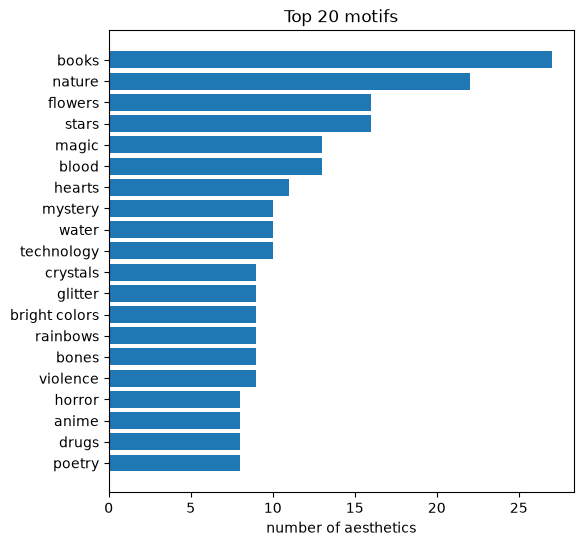

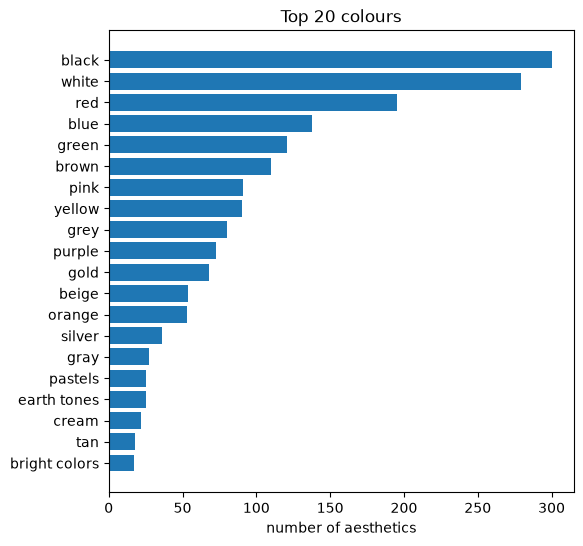

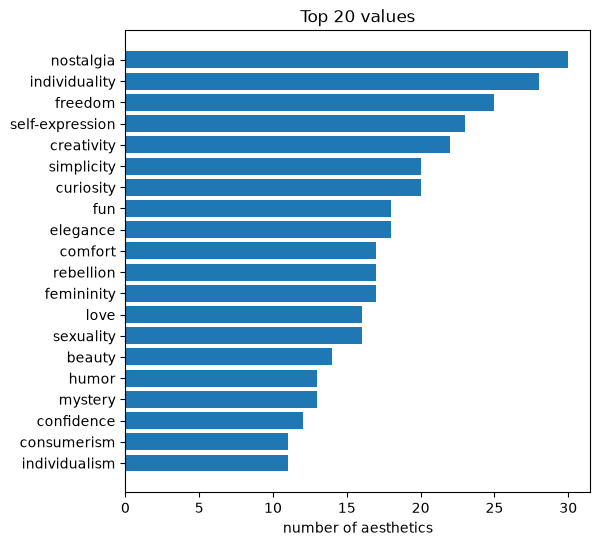

In [25]:
for title, counts in [("motifs", motif_counts), ("colours", colour_counts), ("values", value_counts)]:
  top = counts.head(20)
  plt.figure(figsize=(6, 6))
  plt.barh(top.index[::-1], top.values[::-1])
  plt.title("Top 20 " + title)
  plt.xlabel("number of aesthetics")
  plt.show()

### Aesthetics per decade and era

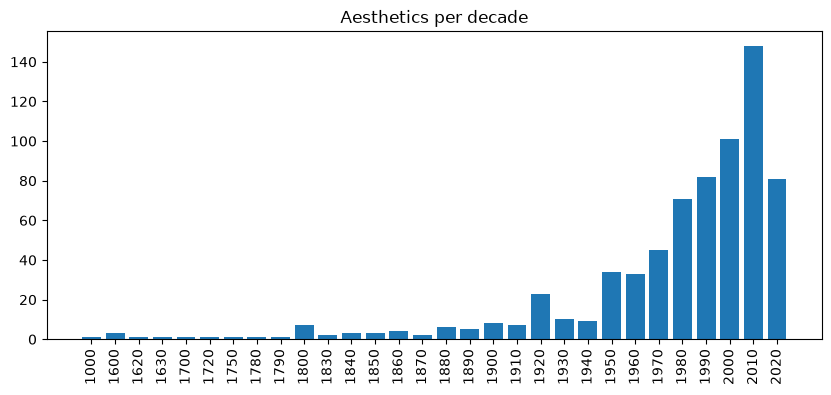

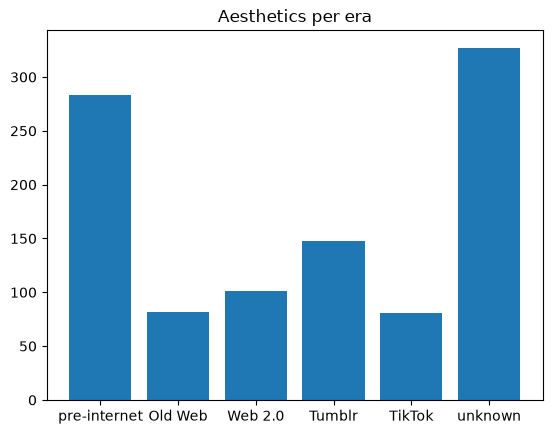

In [26]:
decade_counts = hf_df["decade"].value_counts().sort_index()

plt.figure(figsize=(10, 4))
plt.bar(decade_counts.index.astype(int).astype(str), decade_counts.values)
plt.xticks(rotation=90)
plt.title("Aesthetics per decade")
plt.show()

era_counts = hf_df["era"].value_counts()[era_order]

plt.bar(era_counts.index, era_counts.values)
plt.title("Aesthetics per era")
plt.show()

### Overview length

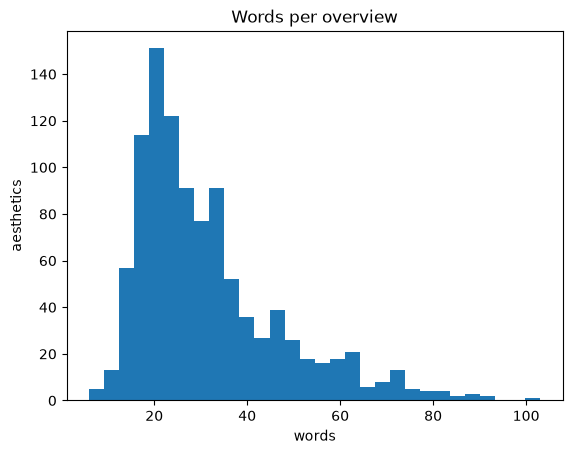

In [27]:
plt.hist(hf_df["overview_words"], bins=30)
plt.xlabel("words")
plt.ylabel("aesthetics")
plt.title("Words per overview")
plt.show()

---
# 4. Save

In [28]:
keep_cols = ["title", "decade", "decade_source", "era", "motifs", "colours", "values", "tags_text", "overview", "overview_words"]

hf_df[keep_cols].to_csv("data/clean/aesthetics_clean.csv", index=False)
print(hf_df[keep_cols].shape)

(1022, 10)


---
# Plan

| Question | Method (week) |
|---|---|
| What words / motifs / colours recur? | counts (above), TF-IDF + SVD topics (wk 11) |
| Clusters tied to internet eras? | TF-IDF → KMeans, colour by era (wk 9–11) |
| Unexpected connections? | nearest neighbours that the wiki doesn't link (`dist`, wk 10) |
| Can language predict the era? | `MultinomialNB` (wk 11) |
| Map for the final piece | t-SNE (wk 10) → JSON |

**Limitations:** the wiki is community-written; decades are fuzzy; era cut-offs are my choice; this is a representation of internet culture, not a definitive taxonomy.

**Sources:** ninar12, *aesthetics-wiki* (Hugging Face) · *AestheticsCV* (Zenodo record 20708760)